In [1]:
import sys 
sys.path.append('../src')

from data_processing.load import load_and_preprocess_data

from data_processing.utils import load_checkpoint, save_checkpoint, run_inference_bnn, run_svi
from models.model import model, model_mw_gamma, model_cf_logitnormal

import jax
import jax.numpy as jnp
import numpy as np
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from jax import random
import time
from numpyro.infer import MCMC, NUTS, Predictive, SVI, Trace_ELBO
import arviz as az
import scipy
from scipy.stats import percentileofscore
from numpyro.infer.autoguide import AutoNormal, AutoDiagonalNormal
from numpyro.optim import Adam
import numpyro.distributions as dist



In [2]:
jax.config.update('jax_num_cpu_devices', 6) # I have 8 physical cores

### Load data and preprocess
- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:
- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)

In [3]:
from operator import itemgetter
data = load_and_preprocess_data()
(X_train, X_test, Y_train_gen, Y_test_gen,
 Y_train_cf, Y_test_cf, Y_train_aval, Y_test_aval,
 sites_meta, feature_cols) = itemgetter(
    "X_train","X_test","Y_train_gen","Y_test_gen",
    "Y_train_cf","Y_test_cf","Y_train_aval","Y_test_aval",
    "sites_meta","feature_cols"
)(data)


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:60: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


### Simple BNN
input: (timestamps, wind parks, features)
output: (timestamps)


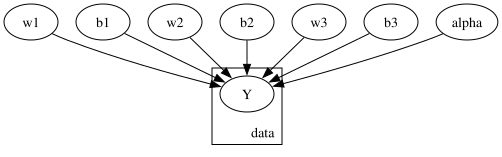

In [4]:
import numpyro
numpyro.render_model(
    model,
    model_args=(X_test,),
)

In [5]:
# args = {
#     'num_warmup': 40,
#     'num_samples': 60,
#     'num_chains': 5,
# }
args = dict(
    num_warmup=50,
    num_samples=100,
    num_chains=1,
)

rng_key, rng_key_predict = random.split(random.PRNGKey(0))

Run MCMC

In [16]:
# simple BNN, but already with Gamma distribution, without softplus, bounded below at 0
samples = run_inference_bnn(model, args, rng_key, X_train, Y_train_gen)

sample: 100%|██████████| 150/150 [01:48<00:00,  1.38it/s, 14 steps of size 2.56e-03. acc. prob=0.71] 


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     alpha      2.01      0.02      2.01      1.97      2.03     20.62      1.03
     b1[0]     -0.91      0.04     -0.91     -0.97     -0.86      3.74      1.79
     b1[1]     -0.97      0.03     -0.97     -1.04     -0.95      8.11      1.10
     b1[2]     -0.83      0.04     -0.82     -0.90     -0.78     13.22      1.19
     b1[3]     -0.97      0.05     -0.98     -1.02     -0.90      3.08      2.62
     b1[4]      0.97      0.07      1.00      0.84      1.04      3.54      1.78
     b1[5]      2.02      0.12      1.99      1.88      2.23      3.44      2.28
     b1[6]     -1.24      0.04     -1.23     -1.29     -1.20      4.41      1.54
     b1[7]      0.42      0.05      0.42      0.35      0.49     31.89      1.00
     b1[8]     -2.43      0.06     -2.42     -2.49     -2.37      6.20      1.51
     b1[9]      2.56      0.17      2.57      2.40      2.61     11.20      1.00
    b1[10]      0.05      0

In [17]:
preds_MCMC = Predictive(model, samples)(rng_key_predict, X_test)['Y']

In [32]:
# Gamma distribution and softplus, seperate mu and k, bounded below at 0
samples_gamma = run_inference_bnn(model_mw_gamma, args, rng_key, X_train, Y_train_gen)


sample: 100%|██████████| 150/150 [12:48<00:00,  5.12s/it, 1023 steps of size 6.22e-03. acc. prob=0.89]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]      2.06      0.52      2.01      1.13      2.77      4.47      1.07
     b1[1]     -1.84      0.38     -1.80     -2.28     -1.34      4.04      2.08
     b1[2]      0.87      0.28      0.79      0.53      1.40      6.23      1.39
     b1[3]     -0.19      0.16     -0.14     -0.40      0.01      7.03      1.33
     b1[4]     -4.37      0.40     -4.37     -5.00     -3.81     33.81      1.06
     b1[5]      0.11      0.54      0.20     -0.62      0.84      2.85      3.24
     b1[6]     -0.88      0.82     -0.75     -1.85      0.17      3.90      1.73
     b1[7]     -0.52      0.50     -0.22     -1.45     -0.10      3.65      1.63
     b1[8]     -0.15      0.09     -0.16     -0.26      0.01     17.26      1.16
     b1[9]      1.27      0.21      1.30      0.97      1.56     20.39      1.11
    b1[10]      1.98      0.38      1.95      1.27      2.48      6.97      1.01
    b1[11]      1.36      0

In [33]:
preds_MCMC_mw_gamma = Predictive(model_mw_gamma, samples_gamma)(rng_key_predict, X_test)['Y']

In [12]:
# Logit Normal, bounded between 0 and 1
samples_logitnormal = run_inference_bnn(model_cf_logitnormal, args, rng_key, X_train, Y_train_cf)

sample: 100%|██████████| 150/150 [19:25<00:00,  7.77s/it, 1023 steps of size 1.82e-03. acc. prob=0.91]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]     -0.72      0.28     -0.76     -1.16     -0.35      3.72      1.78
     b1[1]      1.05      0.35      1.00      0.60      1.57      2.86      2.60
     b1[2]      1.85      0.21      1.94      1.48      2.06      6.28      1.14
     b1[3]     -1.12      0.23     -1.19     -1.35     -0.69      3.84      1.79
     b1[4]     -1.02      0.22     -0.94     -1.33     -0.74      3.15      2.02
     b1[5]     -0.05      0.12     -0.07     -0.21      0.14      3.13      2.20
     b1[6]      0.51      0.29      0.58      0.12      0.80      5.64      1.21
     b1[7]     -1.60      0.33     -1.51     -2.03     -1.16      2.72      3.02
     b1[8]     -0.19      0.13     -0.17     -0.45     -0.03      5.28      1.52
     b1[9]     -0.88      0.14     -0.89     -1.04     -0.76     28.82      0.99
    b1[10]     -0.70      0.15     -0.71     -0.91     -0.53     19.86      1.10
    b1[11]      1.57      0

In [13]:
preds_MCMC_cf_lgit = jax.nn.sigmoid(Predictive(model_cf_logitnormal, samples_logitnormal)(rng_key_predict, X_test)['y_star'])

In [13]:
save_checkpoint(samples, "model", args, rng_key, target="gen")

Saved checkpoint for model 'model': ../../checkpoints/model_2025-10-31_10-18-50_gen.pkl


'../../checkpoints/model_2025-10-31_10-18-50_gen.pkl'

Load checkpoint (MCMC)

In [ ]:
state_ckp = load_checkpoint(file_name='model_2025-10-23_09-03-57_gen') # model_2025-10-21_14-28-15_gen, model_2025-10-23_09-03-57_gen
samples_ckp = state_ckp['samples']
args_ckp = state_ckp['args']
rng_key_ckp = state_ckp['rng_key']
rng_key_ckp, rng_key_predict_ckp = random.split(rng_key_ckp)

In [119]:
preds_MCMC_ckp = Predictive(model, samples_ckp)(rng_key_predict_ckp, X_test)['Y']

Run VI

In [45]:
guide = AutoDiagonalNormal(model_cf_logitnormal)
svi_result = run_svi(model_cf_logitnormal, guide, rng_key, X_train, Y_train_cf, num_steps=5000, lr=1e-4)
params = svi_result.params
preds_VI = jax.nn.sigmoid(Predictive(model_cf_logitnormal, guide=guide, params=params, num_samples=500)(rng_key_predict, X_test)['y_star'])


Final ELBO loss: 3308700416.000


### Evaluation

In [34]:
preds = preds_MCMC_mw_gamma
# CF: preds_MCMC and preds_VI
# Gen: preds_MCMC_ckp


In [35]:
preds_mean = preds.mean(axis=0)

# Percentiles, no assumption about shape of distribution, central 95% interval
# 95% of samples fall here
percentiles = np.percentile(preds, [2.5, 97.5], axis=0)
median = np.percentile(preds, 50, axis=0)

# Assumes posterior is Normal, symmetric around mean,
# If it's normal, 95% if samples fall here
preds_std = preds.std(axis=0)
normal_lower = preds_mean - 1.96 * preds_std
normal_upper = preds_mean + 1.96 * preds_std

# HDI (high densitiy interval), narrowest possible interval 
# Most probable 95% region
hdi = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)

# Widths of different intervals (90% CI)
hdi_avg_width = (hdi[:,1]-hdi[:,0]).mean()
percentile_avg_width = (percentiles[1]-percentiles[0]).mean()
normal_ci_avg_width = (normal_upper - normal_lower).mean()

print(f"Percentile width: {percentile_avg_width}")
print(f"HDI width: {hdi_avg_width}")
print(f"Normal width: {normal_ci_avg_width}")


Percentile width: 215.65496123108426
HDI width: 206.58607705112226
Normal width: 227.73513793945312


In [36]:

inside = (Y_test_gen >= percentiles[0]) & (Y_test_gen <= percentiles[1])
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (Y_test_gen <= median).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")



Empirical coverage (0.025–0.975): 0.896
Below median (should be ~0.5): 0.357


In [37]:
rmse = jnp.sqrt(jnp.mean((preds_mean - Y_test_gen) ** 2))
print("Test RMSE (gen prediction):", rmse)

Test RMSE (gen prediction): 67.79985


In [24]:
inside = (Y_test_cf >= percentiles[0]) & (Y_test_cf <= percentiles[1])
coverage_90 = inside.mean()
print(f"\nEmpirical coverage cf (0.025–0.975): {coverage_90:.3f}")

below_median = (Y_test_cf <= median).mean()
print(f"Below median cf (should be ~0.5): {below_median:.3f}")


Empirical coverage cf (0.025–0.975): 0.884
Below median cf (should be ~0.5): 0.379


In [25]:
rmse = jnp.sqrt(jnp.mean((preds_mean * Y_test_aval - Y_test_gen) ** 2))
print("Test RMSE (cf prediction):", rmse)

Test RMSE (cf prediction): 69.54373


Empirical coverage of percentiles

### Plots

Variational Inference loss

Final ELBO loss: 3308700416.000


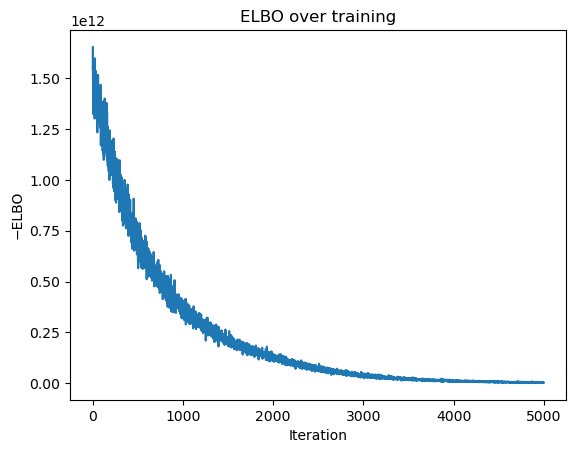

In [54]:
losses = svi_result.losses
print(f"Final ELBO loss: {losses[-1]:.3f}")
plt.plot(losses)
plt.title("ELBO over training")
plt.xlabel("Iteration")
plt.ylabel("−ELBO")
plt.show()


Residuals on training dataset

In [145]:
# positive residuals correspond to missed peaks
# positive tail: in general more underpredictions (train data)
pred_train_mcmc = Predictive(model, samples_ckp)(rng_key_predict_ckp, X_train)['Y']
#pred_train_vi = Predictive(model, guide=guide, params=params, num_samples=500)(rng_key_predict, X_train)['Y']


In [146]:

pred_train = pred_train_mcmc # or pred_train_mcmc


skew: 0.84045607


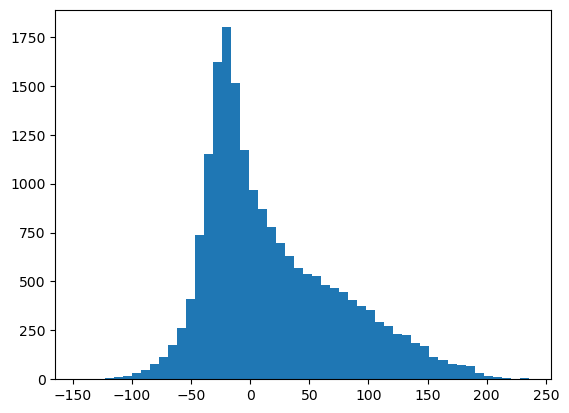

In [147]:
yhat = jnp.mean(pred_train, axis=0)
resid = Y_train_gen - yhat
print("skew:", scipy.stats.skew(np.array(resid)))
plt.hist(np.array(resid), bins=50); plt.show()



Different intervals (percentile vs. hdi vs. normal)

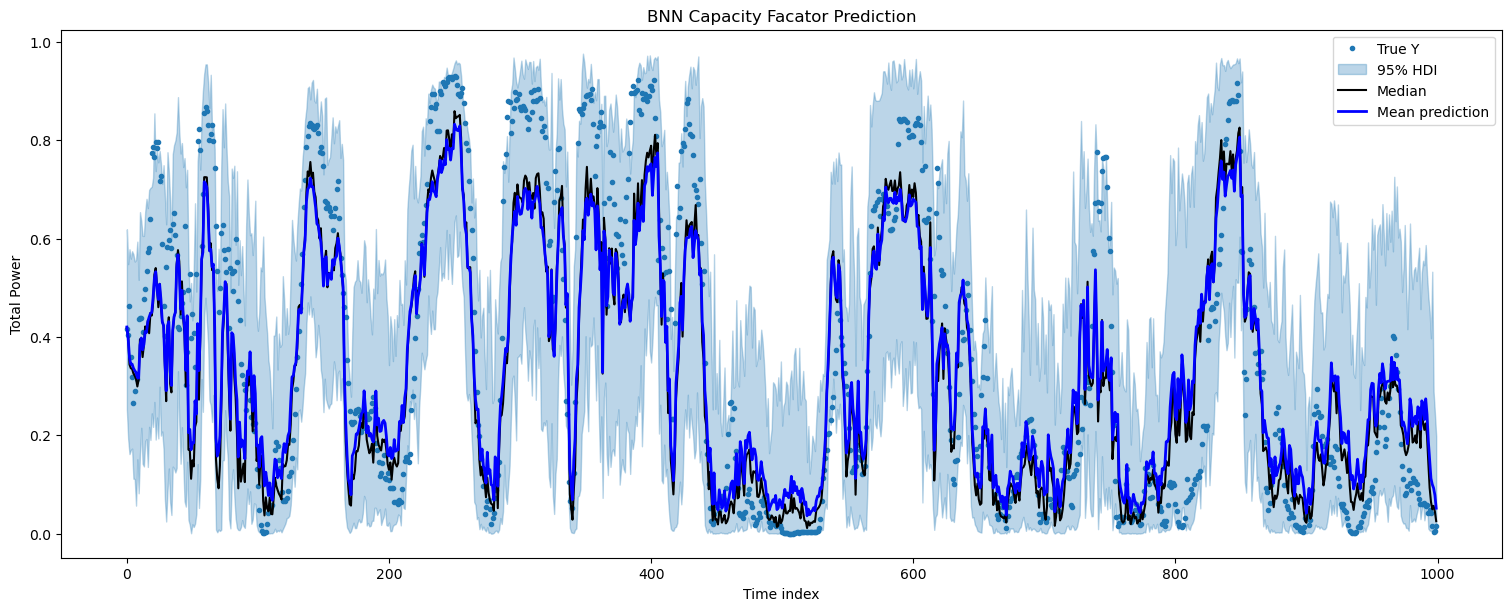

In [26]:
# Plot 90% CI
n_plot = 1000
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(Y_test_cf[:n_plot], ".", label="True Y")
#ax.fill_between(np.arange(n_plot), normal_lower[:n_plot], normal_upper[:n_plot], label='Normal 95% CI', color="green", alpha=0.5)
ax.fill_between(np.arange(n_plot), hdi[:n_plot, 0], hdi[:n_plot, 1], color="C0", label="95% HDI", alpha=.3)
#ax.fill_between(np.arange(n_plot), percentiles[0, :n_plot], percentiles[1, :n_plot], label="Percentile 95% CI", color="lightblue", alpha=0.7)
ax.plot(median[:n_plot], label="Median", color="black")
ax.plot(preds_mean[:n_plot], "b", lw=2, label="Mean prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="BNN Capacity Facator Prediction")
ax.legend()
plt.show()


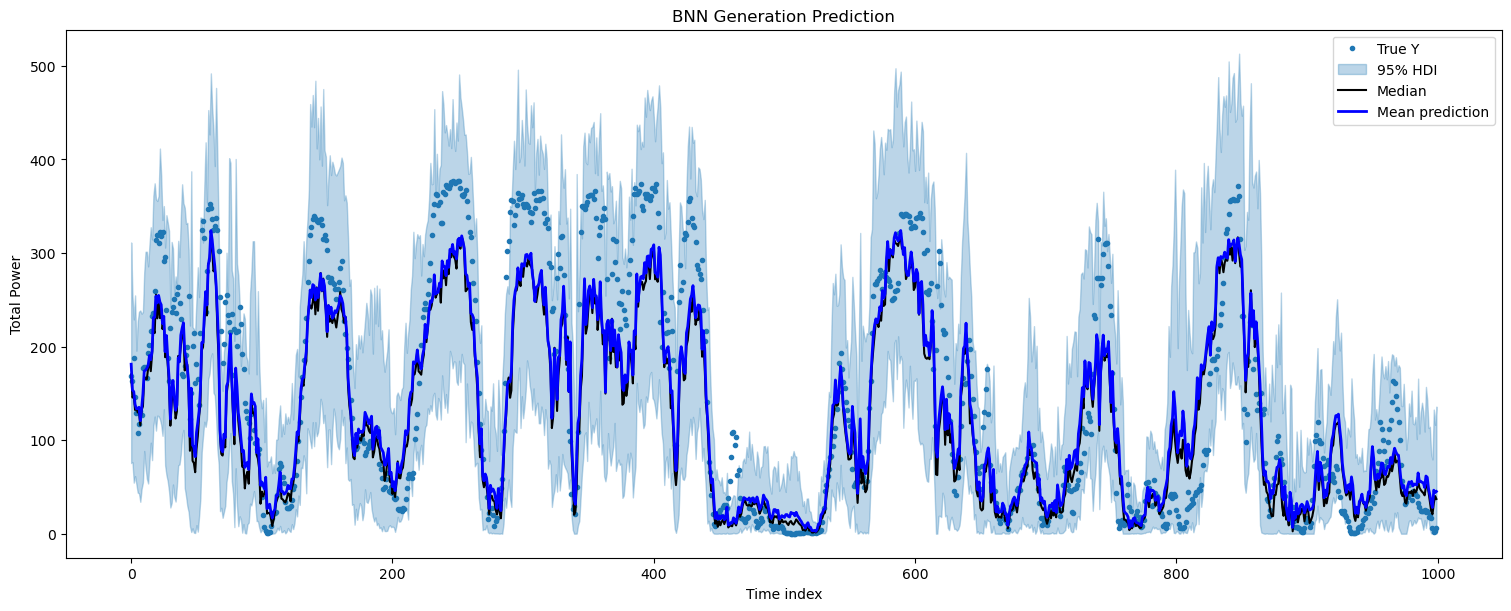

In [38]:
# Plot 90% CI
n_plot = 1000
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(Y_test_gen[:n_plot], ".", label="True Y")
#ax.fill_between(np.arange(n_plot), normal_lower[:n_plot], normal_upper[:n_plot], label='Normal 95% CI', color="green", alpha=0.5)
ax.fill_between(np.arange(n_plot), hdi[:n_plot, 0], hdi[:n_plot, 1], color="C0", label="95% HDI", alpha=.3)
#ax.fill_between(np.arange(n_plot), percentiles[0, :n_plot], percentiles[1, :n_plot], label="Percentile 95% CI", color="lightblue", alpha=0.7)
ax.plot(median[:n_plot], label="Median", color="black")
ax.plot(preds_mean[:n_plot], "b", lw=2, label="Mean prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="BNN Generation Prediction")
ax.legend()
plt.show()


Stacked HDI

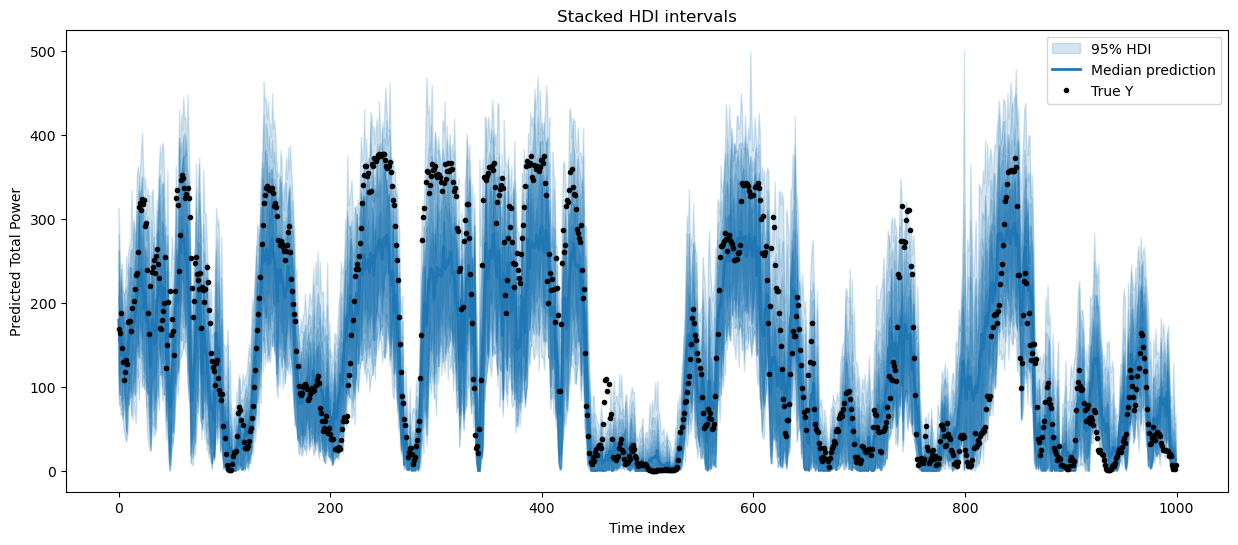

In [65]:
# Only plot first n_plot timesteps
n_plot = 1000

# Compute multiple HDI levels
hdi_probs = np.arange(0.05, 1.0, 0.05)
preds_hdi = np.expand_dims(preds, axis=0)
hdis = {float(p): az.hdi(preds_hdi, hdi_prob=float(p)) for p in hdi_probs}

X_new = np.arange(n_plot)
median = np.percentile(preds, 50, axis=0)

plt.figure(figsize=(15, 6))
max_p = max(hdis.keys())
for p in hdi_probs:
    hdi = hdis[p][:n_plot]
    alpha = 0.2 * float(p)
    label = f'{int(p*100)}% HDI' if p == max_p else None
    plt.fill_between(X_new, hdi[:, 0], hdi[:, 1], color='C0', alpha=alpha, label=label)

plt.plot(X_new, median[:n_plot], color='C0', lw=2, label='Median prediction')
plt.plot(Y_test_gen[:n_plot], ".", color="black", label="True Y")
plt.title("Stacked HDI intervals")
plt.xlabel("Time index")
plt.ylabel("Predicted Total Power")
plt.legend()
plt.show()


Std noise of model samples

<Axes: title={'center': 'std noise'}>

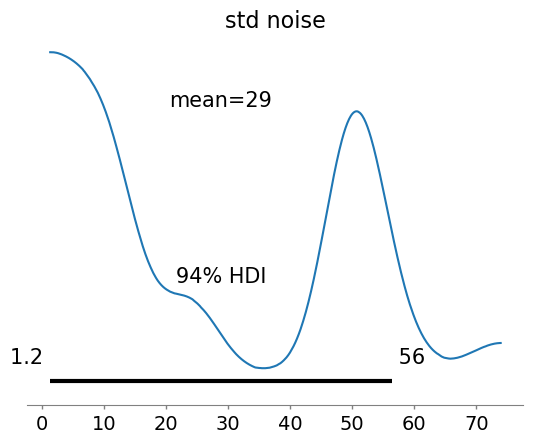

In [65]:
# Plot std noise
az.plot_posterior({'std noise': 1.0 / jnp.sqrt(samples['prec_obs'])})

PIT (Probability Integral Transform)
- Checks calibration of probabilistic forecasts
- Model well-calibrated -> values uniformly distributed
- For each observation $y_i$:
    - Take all model’s predictive samples for that data point
    - Compute how many of those samples are less than or equal to the actual observed value
    - PIT value $u_i = P_{\hat{Y_i}}​​(Y\leq y)$
    - with MCMC: $u_i \approx \frac{1}{S} \sum_{s=1}^S 1[y_i^{(s)}\leq y_i]$

PIT mean: 0.7161846367422491 (should be uniform if calibrated)


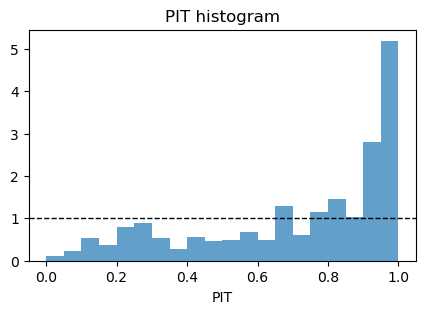

In [66]:
pits = np.array([percentileofscore(preds[:, t], Y_test_gen[t], kind='mean') / 100.0 for t in range(preds.shape[1])])
pits_mean = pits.mean()
print(f"PIT mean: {pits_mean} (should be uniform if calibrated)")

plt.figure(figsize=(5,3))
plt.hist(pits, bins=20, range=(0,1), density=True, alpha=0.7)
plt.axhline(1.0, color='k', ls='--', lw=1)  # reference
plt.xlabel("PIT")
plt.title("PIT histogram")
plt.show()

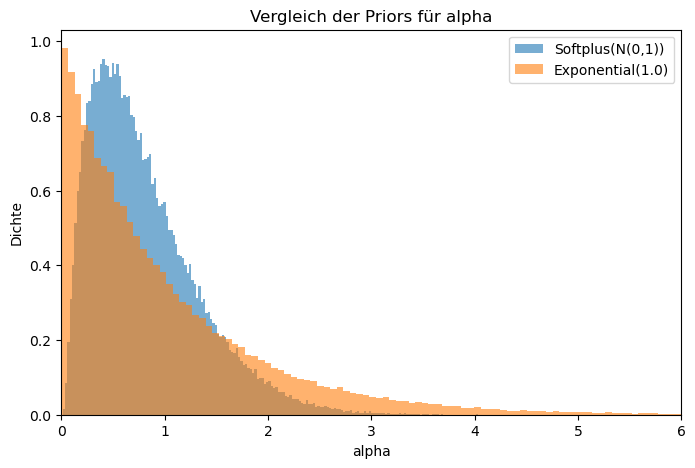

In [6]:
num_samples = 100000
rng_key = jax.random.key(0)

alpha_normal = dist.Normal(0, 1.0).sample(rng_key, (num_samples,))
alpha_normal = jax.nn.softplus(alpha_normal) + 1e-6
alpha_expon = dist.Exponential(1.0).sample(rng_key, (num_samples,))

plt.figure(figsize=(8, 5))
plt.hist(alpha_normal, bins=200, density=True, alpha=0.6, label="Softplus(N(0,1))")
plt.hist(alpha_expon, bins=200, density=True, alpha=0.6, label="Exponential(1.0)")

plt.xlim(0, 6)
plt.xlabel("alpha")
plt.ylabel("Dichte")
plt.title("Vergleich der Priors für alpha")
plt.legend()
plt.show()
